# Лабораторная работа № 3
## Непрерывная оптимизация графов с релаксацией

Дмитрий Андреевич Василенко. Вариант № 7.

В работе выбираем, какие слагаемые оставить в уравнениях Эйлера. Для каждого варианта подбираем коэффициенты и считаем ошибку. При выборе учитываем число слагаемых и результаты проверок из второй лабораторной. Все предложенные поиском графы сохраняем.

За основу взята [вторая работа Ивана Папая](https://github.com/papayiv/euler-quadrants-lab/blob/c401635cd8966dec498f17dcff242a3b705fde29/notebooks/lab2_interventions.ipynb). В ней Иван продолжил мою первую работу по уравнениям Эйлера. Из его кода используем набор слагаемых, условное перемешивание входов, блочный бутстреп и правило сохранения групп рёбер. Для поиска графов применяем метод варианта 7: непрерывную релаксацию.


## 1. Запуск

Расчёты находятся в `src/graph_lab/experiments.py`, поиск графов и проверки в `selection.py`, построение рисунков в `plotting.py`. Ноутбук читает сохранённые результаты. Если их нет, он запускает расчёт:

```bash
uv run --locked python scripts/run_lab3.py
```

Для пересчёта после изменения настроек используется та же команда. Скрипт `scripts/build_lab3_notebook.py` собирает ноутбук из текста и ячеек кода.

Модуль Ивана сохранён без изменений в `src/graph_lab/vendor/ivan_interventions.py`. Рядом указаны автор и версия. Чтобы ускорить повторные проверки, новый код заранее считает суммы произведений признаков и откликов.


In [1]:
import json
import os
import subprocess
import sys
from pathlib import Path

import numpy as np
from IPython.display import Image, Markdown, display

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
OUT = ROOT / "results" / "lab3"
complete = False
if (OUT / "metrics.json").exists():
    saved = json.loads((OUT / "metrics.json").read_text())
    complete = set(saved.get("datasets", {})) == {"synthetic", "control", "well"} and (OUT / "comparison.png").exists()
if not complete:
    env = dict(os.environ, PYTHONPATH=str(ROOT / "src"))
    subprocess.run([sys.executable, str(ROOT / "scripts" / "run_lab3.py")],
                   cwd=ROOT, env=env, check=True)
metrics = json.loads((OUT / "metrics.json").read_text())
PARAMS = ["a_x", "a_y", "a_z", "bE_x", "bE_y", "bE_z", "bK_x", "bK_y", "bK_z"]
NAMES = {"synthetic": "Эйлер, ANU 6", "control": "Контроль без K в давлении", "well": "The Well"}
METHODS = {"intervention": "с интервенциями", "ablation": "без интервенций"}

def table(headers, rows):
    display(Markdown("\n".join([
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join(["---"] * len(headers)) + " |",
        *["| " + " | ".join(map(str, row)) + " |" for row in rows],
    ])))

def figure(filename, width=1050):
    path = OUT / filename
    if not path.exists():
        raise FileNotFoundError(f"Пересчитайте эксперименты: отсутствует {path}")
    display(Image(filename=str(path), width=width))

print("Настройки вычислительного эксперимента:")
print(json.dumps(metrics["config"], ensure_ascii=False, indent=2))


Настройки вычислительного эксперимента:
{
  "n_synthetic": 96,
  "n_boot": 100,
  "n_splits": 16,
  "diagnostic_seed": 0,
  "search_seeds": [
    0,
    1,
    2
  ],
  "lambda_complexity": 0.02,
  "lambda_intervention": 0.1,
  "ridge": 1e-05,
  "rounds": 4,
  "steps": 40,
  "samples_per_round": 24,
  "intervention_seed": 1701,
  "selection_rule": "Validation NMSE + lambda_complexity * active_groups/9 + lambda_intervention * training_evidence_disagreement/9",
  "seed_scope": "Search seeds vary gates and graph proposals. Intervention, bootstrap and null-calibration seeds remain fixed.",
  "precommitment": "Splits and default penalties fixed before evaluating test quality. Sensitivity uses validation only."
}


## 2. Модель и возможные графы

Для плотности, импульса и полной энергии $U=(\rho,m_x,m_y,m_z,E)$ записываем модель Ивана:

$$
\partial_t U=-\sum_{d\in\{x,y,z\}}\left[
 a_d\partial_d(Uv_d)+\beta^E_d\partial_dP^E_d-\beta^K_d\partial_dP^K_d\right],
\qquad
P^E_d=(0,Ee_d,Ev_d),\quad P^K_d=(0,Ke_d,Kv_d),
$$

где $v_d=m_d/\rho$, $K=\rho\lVert v\rVert^2/2$. При $a_d=1$ и $\beta^E_d=\beta^K_d=\gamma-1$ получаем обычные уравнения Эйлера с давлением $p=(\gamma-1)(E-K)$. Для $\gamma=1.4$ коэффициенты давления равны $0.4$.

Коэффициенты по каждой координате подбираем отдельно. Равенства $\beta^E_x=\beta^E_y$ и $\beta^K_x=\beta^K_y$ не задаём. Различие оценок может частично компенсировать ошибку численной схемы.

Всего есть девять групп слагаемых. Маска $m\in\{0,1\}^9$ задаёт, какие из них включены: 1 сохраняет группу, 0 удаляет. Для каждой маски подбираем свои веса $w_m$.

| Группа | Физическая роль | Узел для диагностики |
|---|---|---|
| $a_x,a_y,a_z$ | Адвективный перенос по каждой координате | $u,v,w$ соответственно |
| $\beta^E_x,\beta^E_y,\beta^E_z$ | Вклад полной энергии в давление и работу давления | $E$ |
| $\beta^K_x,\beta^K_y,\beta^K_z$ | Поправка на кинетическую энергию в давлении | $K$ |

Операции и направления связей заданы уравнением. Мы только удаляем группы из исходного графа, поэтому новые циклы возникнуть не могут. Отдельная проверка ацикличности не нужна. Для девяти групп есть $2^9=512$ масок. Одна группа может содержать несколько рёбер.

Все данные здесь двумерные, поэтому столбцы трёх $z$-слагаемых равны нулю. По этим данным нельзя оценить их коэффициенты. В трёхмерном течении необходимость этих слагаемых нужно проверить заново.


## 3. Данные и разделение выборки

В матрицу $X$ записываем сглаженные пространственные производные слагаемых, в $y$ записываем сглаженную временную производную $U$. При вычислении производной учитываем неравные шаги по времени. Каждое уравнение делим на среднеквадратичное значение отклика на обучении (RMS). Для нулевого канала $m_z$ берём среднее RMS двух других компонент импульса. Для валидации и теста используем те же делители.

Используются три набора:

1. **Обычная синтетика.** Начальные условия ANU, случай 6. Расчёт выполнен методом Русанова из первой работы при $\gamma=1.4$.
2. **Контроль без $K$.** Те же начальные условия, но расчёт использует давление $p=(\gamma-1)E$. В данных заранее отсутствует вклад кинетической энергии в давление. Проверяем, найдёт ли алгоритм это изменение.
3. **The Well.** Траектория, рассчитанная в Clawpack и сохранённая в первой работе. Она получена другим решателем. Все три набора численные; физических измерений здесь нет.

Контроль с $p=(\gamma-1)E$ задаёт искусственную систему законов сохранения. Для неё нужно изменить максимальную скорость волн в потоке Русанова и условии CFL:

$$s_d=\frac{\gamma+1}{2}|v_d|+\sqrt{\frac{(\gamma-1)^2}{4}v_d^2+\frac{\gamma p}{\rho}}.$$

Собственные значения якобиана потока равны $v_d$ кратности 3 и $(\gamma+1)v_d/2\pm\sqrt{(\gamma-1)^2v_d^2/4+\gamma p/\rho}$. Формула выше даёт наибольший модуль этих значений. Её проверили численно по якобиану. Расчёт находится в `control_solver.py`.

На синтетике обучение, валидация и тест используют разные участки времени с промежутками между ними. В The Well всего семь кадров. Для обучения берём производные с центрами в кадрах 1 и 2, для валидации в кадре 3, для теста в кадре 5. При этом валидационный шаблон `[2,3,4]` и тестовый `[4,5,6]` используют общий кадр 4. Тестовый шаблон не пересекается с обучающими `[0,1,2]` и `[1,2,3]`. Такая проверка оценивает прогноз на более позднем участке той же траектории.

Проверки слагаемых и расчёт порогов используют только обучение. По валидации выбираем граф из архива. Тестовые отклики в оптимизатор не передаём.


In [2]:
rows = []
for key, item in metrics["datasets"].items():
    meta = item["metadata"]
    rows.append([
        NAMES[key], "×".join(map(str, meta["grid"])),
        ", ".join(f"{t:.3g}" for t in meta["train_times"]),
        ", ".join(f"{t:.3g}" for t in meta["validation_times"]),
        ", ".join(f"{t:.3g}" for t in meta["test_times"]),
        meta["n_rows"]["train"], meta["n_train_blocks"],
    ])
table(["Набор", "Сетка", "Время обучения", "Валидация", "Тест", "Строк обучения", "Блоков"], rows)


| Набор | Сетка | Время обучения | Валидация | Тест | Строк обучения | Блоков |
| --- | --- | --- | --- | --- | --- | --- |
| Эйлер, ANU 6 | 96×96×1 | 0.03, 0.05, 0.07, 0.09, 0.11, 0.13 | 0.17, 0.19 | 0.25, 0.27, 0.29 | 173280 | 294 |
| Контроль без K в давлении | 96×96×1 | 0.03, 0.05, 0.07, 0.09, 0.11, 0.13 | 0.17, 0.19 | 0.25, 0.27, 0.29 | 173280 | 294 |
| The Well | 64×64×1 | 0.015, 0.03 | 0.06 | 0.12 | 25000 | 98 |

## 4. Критерий Ивана

Проверка каждого слагаемого состоит из двух частей.

**Информативность.** Задаём априорное распределение весов $w\sim\mathcal N(0,100I)$. По линейной модели с гауссовым шумом оцениваем его дисперсию и распределение весов после обучения. Считаем, насколько оно отличается от априорного:

$$I_j=\operatorname{KL}\!\left(p(w_j\mid D_{\rm train})\,\|\,p(w_j)\right).$$

Если $I_j<1$ нат, считаем, что данных недостаточно для сохранения слагаемого по этому правилу. Сам порог выбран для диагностики и не доказывает, что параметр нельзя определить. Для этой проверки используем ковариацию гауссовой модели. Бутстреп нулевого столбца всегда давал бы нулевые оценки и скрывал бы неопределённость веса.

**Реакция на изменение входа.** Делим точки на интервалы по плотности. Внутри каждого интервала перемешиваем значения выбранного узла и пересчитываем зависящие от него величины в $X$. Блочным бутстрепом получаем распределения оценок весов до и после перемешивания. Расстояние между ними считаем как

$$J_j=\tfrac12\left[\operatorname{KL}(P_j\|Q_j)+\operatorname{KL}(Q_j\|P_j)\right].$$

Здесь используется половина суммы KL в двух направлениях, как в коде Ивана. $P_j$ и $Q_j$ получены гауссовым приближением бутстреп-распределений MAP-оценок, то есть наиболее вероятных весов с учётом априорного распределения. Бутстреп показывает разброс оценок на повторных выборках. Его нельзя считать точным апостериорным распределением весов.

Для выбора порога несколько раз разбиваем блоки данных на случайные половины и сравниваем оценки без перемешивания входа. Обозначим 95%-квантиль этих расстояний через $t_j$. Сохраняем группу, если выполнены обе проверки:

$$q_j=\mathbf1\{I_j\ge1\}\mathbf1\{J_j>t_j\}.$$

Такой порог оценивает обычный разброс расстояний на этих данных. Он не гарантирует уровень значимости 5%; поправки на множество проверок здесь нет.

При перемешивании отклик $\partial_tU$ остаётся прежним. Поэтому проверяем чувствительность модели к входу. Физическое течение после $do$-вмешательства здесь не рассчитывается. Перемешивание сохраняет распределение значений узла внутри интервала плотности, но нарушает часть связей с другими величинами и пространственное расположение. В контрольном наборе без $K$ меняем уже само уравнение, по которому получены данные.


## 5. Непрерывная релаксация структуры

Каждой группе назначаем коэффициент включения $z_j\in[0,1]$. При $z_j=0$ группа выключена. Промежуточные значения позволяют менять структуру плавно. При фиксированном $z$ подбираем веса:

$$
\widehat w(z)=\arg\min_w\left[
\frac{\lVert y-XD_z w\rVert^2}{s}+\kappa\lVert w\rVert^2\right],
\qquad D_z=\operatorname{diag}(z),\quad s=\lVert y\rVert^2.
$$

Для $\kappa>0$ решение единственно:

$$\widehat w(z)=\left(D_zX^\top XD_z+\kappa sI\right)^{-1}D_zX^\top y.$$

Без регуляризации можно уменьшать $z_j$ и увеличивать $w_j$, сохраняя произведение $z_jw_j$. Тогда штраф за размер графа уменьшался бы без изменения предсказания. Штраф $\kappa\lVert w\rVert^2$ ограничивает рост весов.

Подставляем найденные веса в функцию, которую будем минимизировать по $z$:

$$
F(z;q)=\frac{\lVert y-XD_z\widehat w(z)\rVert^2}{s}
+\kappa\lVert\widehat w(z)\rVert^2
+\lambda\frac1{9}\sum_jz_j
+\eta\frac1{9}\sum_j\left[q_j(1-z_j)+(1-q_j)z_j\right].
$$

$F$ используется на обучении, чтобы получать кандидатов. Ниже вводится отдельный критерий $S$, который сравнивает бинарные модели на валидации.

Последнее слагаемое поощряет совпадение маски с решением проверки $q$. Если $q_j=1$, штраф уменьшается при сохранении группы; если $q_j=0$, при её удалении. Так в поиске используется критерий второй работы. Он не требует, чтобы предсказания или распределения весов оставались неизменными после вмешательства.

При фиксированном $q$ производная по $z_j$ равна

$$
\frac{\partial F}{\partial z_j}
=\frac{2\widehat w_j}{s}X_j^\top(XD_z\widehat w-y)
+\frac\lambda9+\frac\eta9(1-2q_j).
$$

Слагаемое с производной $\widehat w(z)$ равно нулю, потому что веса уже минимизируют внутреннюю задачу. Для поиска $z$ используем L-BFGS-B с ограничениями $0\le z_j\le1$.

Идею непрерывных коэффициентов включения используют Louizos et al. (2018) и Yamada et al. (2020). Здесь применена своя схема: оптимизация на отрезке и последующее получение бинарных масок. Алгоритмы hard-concrete и STG целиком не реализованы.


## 6. Алгоритм генерации и выбора графов

Начинаем с полной маски и случайных значений $z_j^{(0)}\sim\operatorname{Uniform}(0.35,0.85)$. Выполняем четыре шага поиска, каждый включает до 40 итераций L-BFGS-B. Перед очередным шагом возвращаем значения $z$ в отрезок $[0.02,0.98]$, чтобы удалённая группа могла включиться снова.

На каждом внешнем шаге:

1. Берём текущую маску. Для проверки группы $j$ добавляем её в модель, если она была удалена.
2. На обучении пересчитываем решение $q$ с учётом текущего набора групп.
3. При фиксированном $q$ оптимизируем $z$ и сохраняем значения $z$ на каждой итерации.
4. Получаем бинарные маски тремя способами: по порогу, по $k$ наибольшим значениям $z_j$ и случайной выборкой $m_j\sim\operatorname{Bernoulli}(z_j)$. Используем пороги $0.01,0.05,0.1,0.25,0.5,0.75$ и $k=1,\ldots,9$. Несколько порогов нужны потому, что из-за регуляризации даже у важной группы $z_j$ может быть меньше $0.5$. Сохраняем все маски, включая повторы.
5. Для каждой маски заново подбираем веса на обучении и считаем критерий на валидации.

Чтобы сравнивать графы разных шагов по одному правилу, в итоговом критерии используем общий вектор $q^{\rm ref}$. Его считаем на обучении для полной модели:

$$
S(m)=\underbrace{\frac{\lVert y_{\rm val}-X_{\rm val}D_m\widehat w(m)\rVert^2}
{\lVert y_{\rm val}\rVert^2}}_{\operatorname{NMSE}_{\rm val}}
+\lambda\frac{\lVert m\rVert_0}{9}
+\eta\frac1{9}\sum_j\left[q_j^{\rm ref}(1-m_j)+(1-q_j^{\rm ref})m_j\right].
$$

$q$ обновляется при поиске и влияет на следующие маски. $q^{\rm ref}$ остаётся постоянным, чтобы оценки графов из разных шагов были сравнимы.

При $\kappa>0$ веса для фиксированного $z$ определяются однозначно. Коэффициенты включения остаются в $[0,1]$, а маски могут только удалять группы из исходного графа. Из архива выбираем граф с наименьшим $S$. Поиск не гарантирует глобальный минимум непрерывной задачи или восстановление истинной структуры.

Отдельно перебираем все 512 масок и находим точный минимум $S$. Сравниваем его с результатом поиска, но найденную перебором маску в архив не добавляем. Нулевой разрыв означает, что поиск нашёл минимум выбранного критерия среди этих 512 вариантов.


## 7. Результаты интервенционной диагностики

Ниже показаны проверки полной модели на обучении. Числа могут отличаться от работы Ивана, поскольку здесь данные разделены иначе.


### Эйлер, ANU 6

| Группа | KL к априорному, нат | Сдвиг J | Порог | Решение |
| --- | --- | --- | --- | --- |
| a_x | 9.01 | 1.2e+03 | 3.32 | сохранить |
| a_y | 9.05 | 983 | 4.39 | сохранить |
| a_z | 0 | 0 | 0 | исключить |
| bE_x | 8.04 | 118 | 1.55 | сохранить |
| bE_y | 8.33 | 41.2 | 4.87 | сохранить |
| bE_z | 0 | 0 | 0 | исключить |
| bK_x | 7.74 | 8.94 | 2.37 | сохранить |
| bK_y | 7.93 | 1.01 | 4.34 | исключить |
| bK_z | 0 | 0 | 0 | исключить |

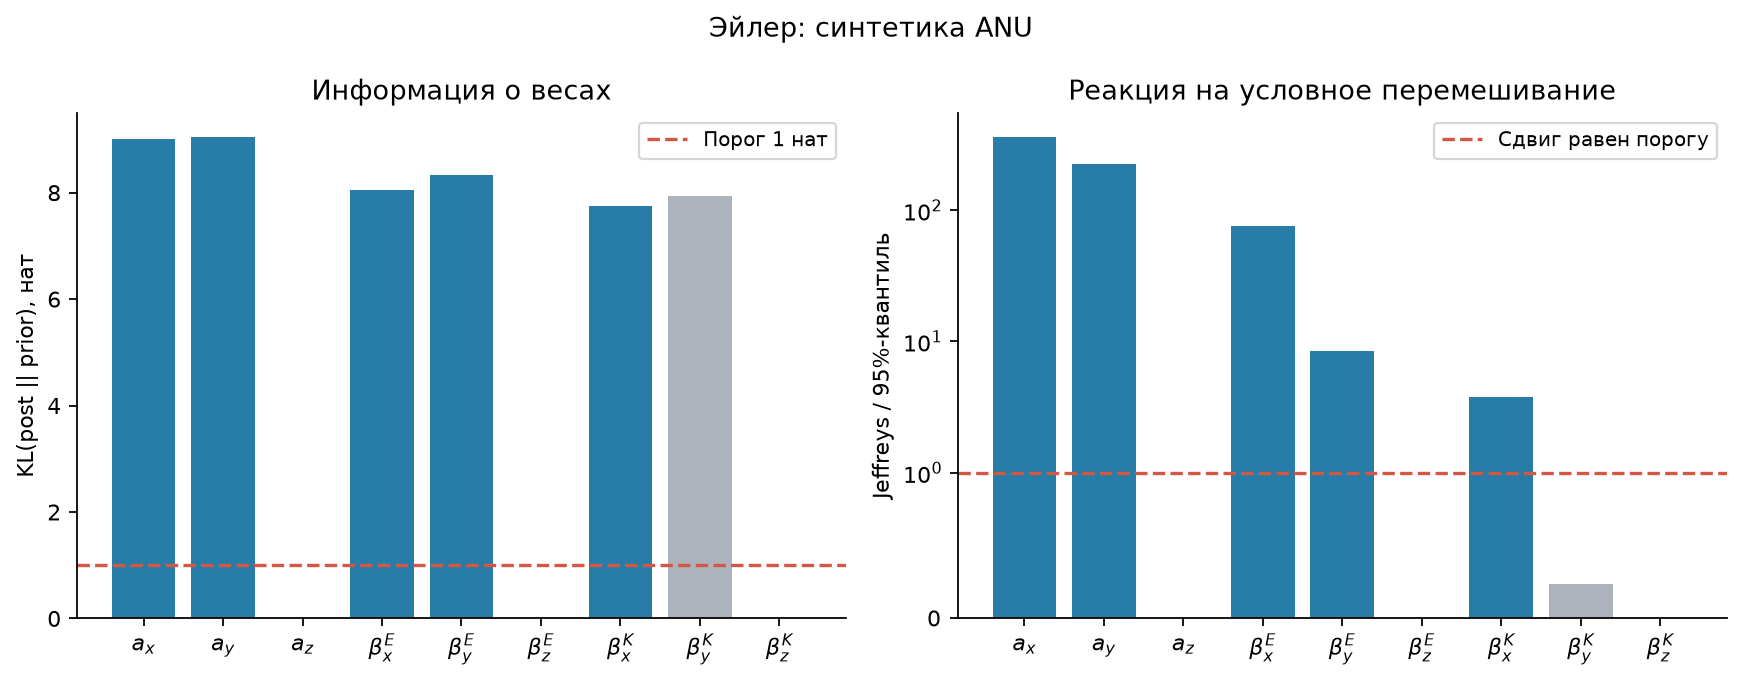

### Контроль без K в давлении

| Группа | KL к априорному, нат | Сдвиг J | Порог | Решение |
| --- | --- | --- | --- | --- |
| a_x | 9.08 | 874 | 3.26 | сохранить |
| a_y | 8.98 | 701 | 4.45 | сохранить |
| a_z | 0 | 0 | 0 | исключить |
| bE_x | 8.11 | 104 | 2.18 | сохранить |
| bE_y | 8.38 | 36.7 | 7.31 | сохранить |
| bE_z | 0 | 0 | 0 | исключить |
| bK_x | 8.26 | 1.03 | 7.41 | исключить |
| bK_y | 8.49 | 0.0151 | 4.81 | исключить |
| bK_z | 0 | 0 | 0 | исключить |

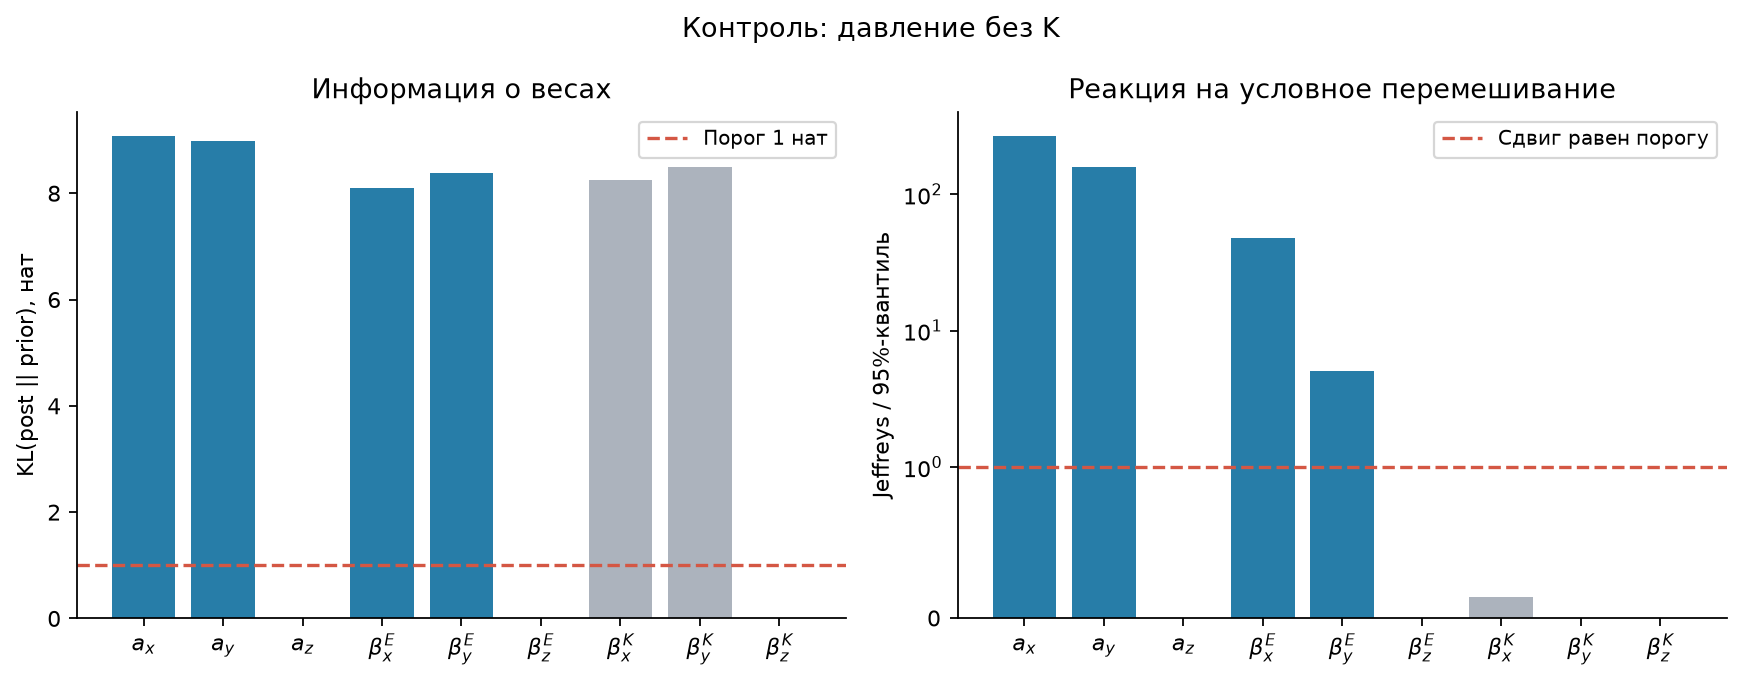

### The Well

| Группа | KL к априорному, нат | Сдвиг J | Порог | Решение |
| --- | --- | --- | --- | --- |
| a_x | 9.62 | 8.73e+03 | 3.84 | сохранить |
| a_y | 8.73 | 2.3e+03 | 6.28 | сохранить |
| a_z | 0 | 0 | 0 | исключить |
| bE_x | 9.98 | 326 | 6.06 | сохранить |
| bE_y | 9.36 | 22.6 | 5.77 | сохранить |
| bE_z | 0 | 0 | 0 | исключить |
| bK_x | 8.73 | 27.5 | 8.05 | сохранить |
| bK_y | 7.6 | 6.02 | 10.6 | исключить |
| bK_z | 0 | 0 | 0 | исключить |

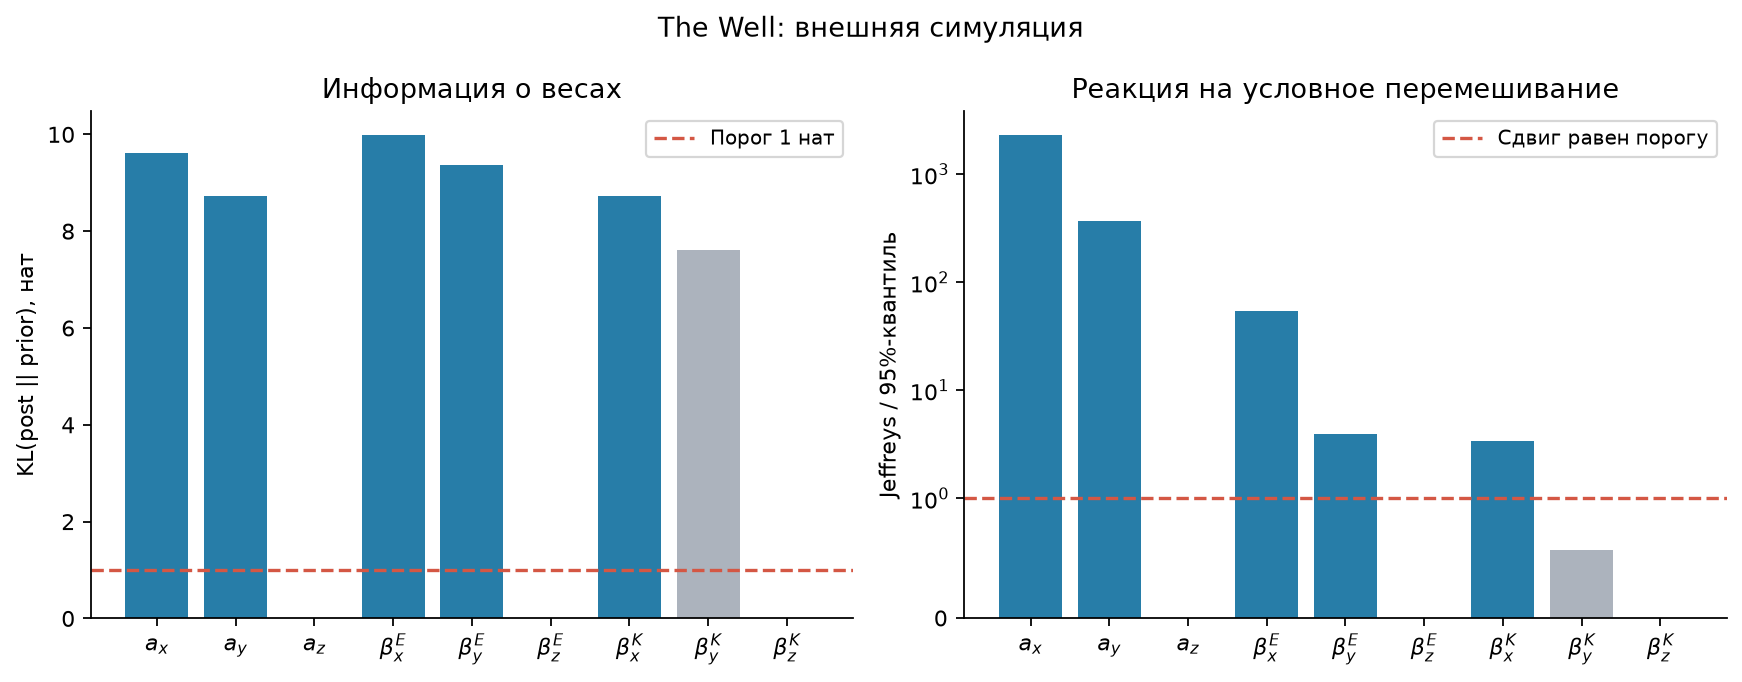

In [3]:
for key, item in metrics["datasets"].items():
    display(Markdown(f"### {NAMES[key]}"))
    d = item["reference_diagnostics"]
    rows = [[PARAMS[j], f"{d['info'][j]:.3g}", f"{d['shift'][j]:.3g}",
             f"{d['null_q'][j]:.3g}", "сохранить" if d["keep"][j] else "исключить"]
            for j in range(9)]
    table(["Группа", "KL к априорному, нат", "Сдвиг J", "Порог", "Решение"], rows)
    figure(f"{key}_diagnostics.png")


## 8. Как меняется граф при поиске

Линии показывают значения $z$ на итерациях поиска. Рядом изображены полученные графы. Их узлы объединяют группы операций, поэтому число связей на рисунке отличается от исходного графа с 18 вершинами.

В архив также добавлены полная и пустая маски для сравнения. Значения $z$ используются в оптимизации и при случайном выборе масок. Они не оценивают вероятность существования физической связи.


### Эйлер, ANU 6

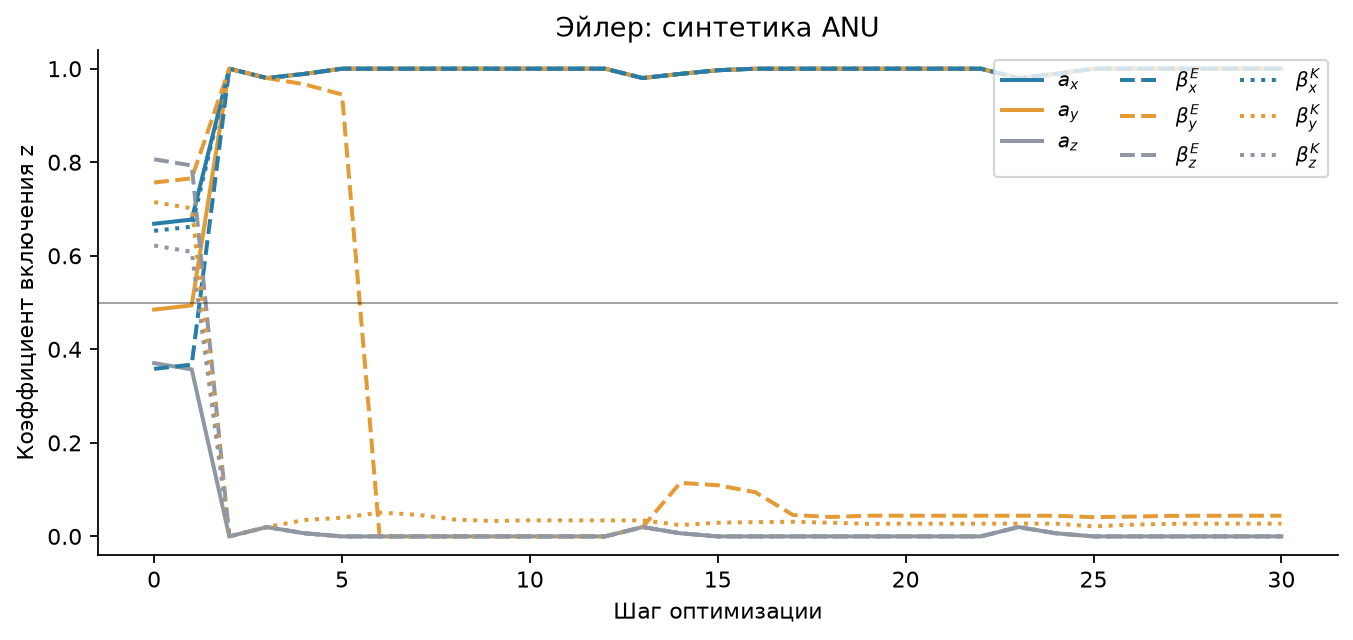

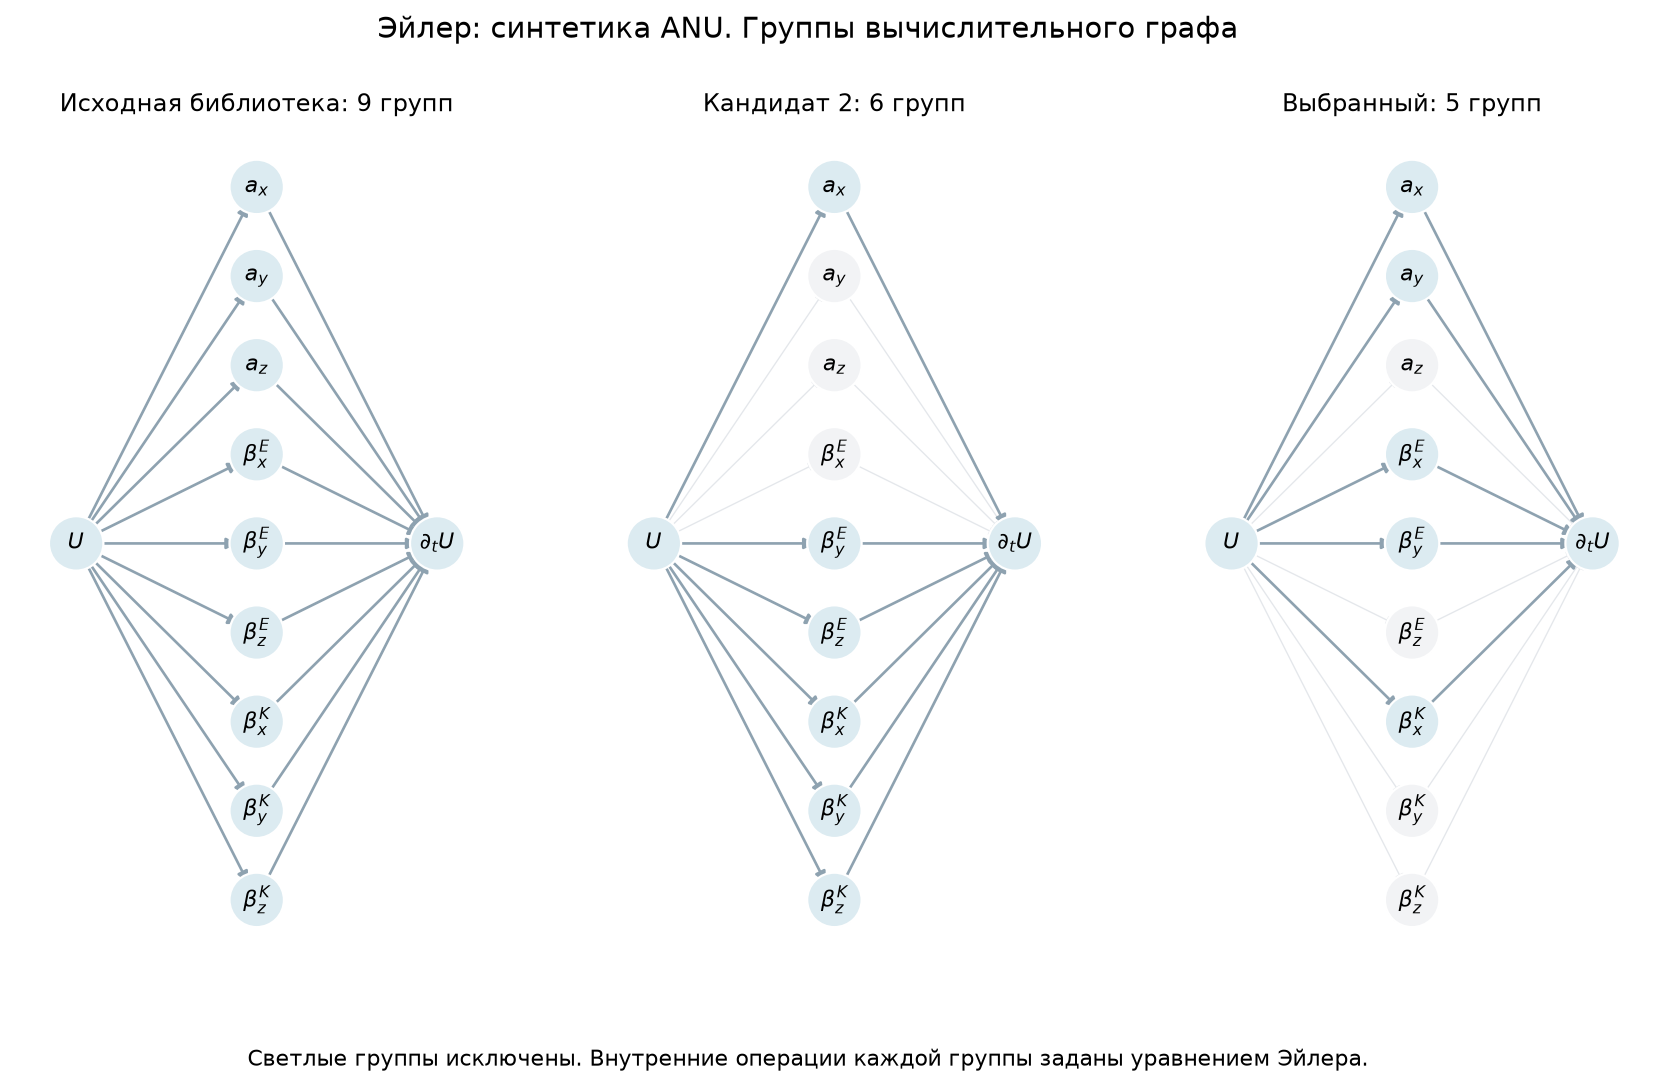

### Контроль без K в давлении

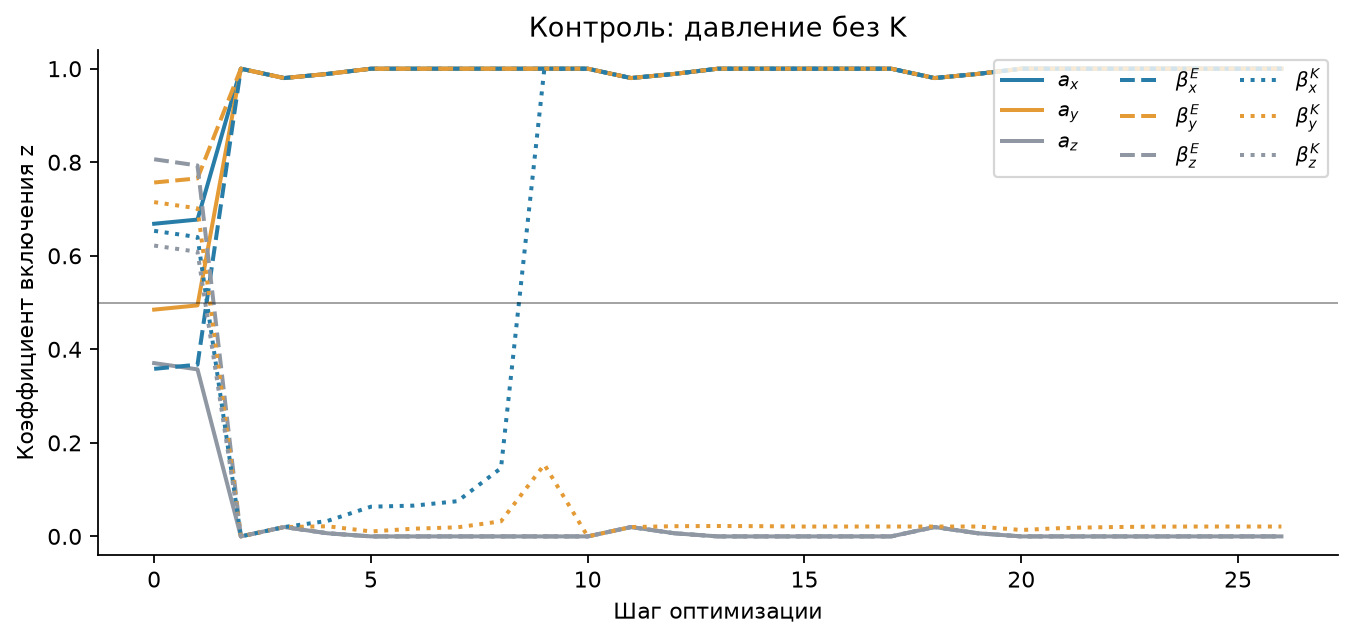

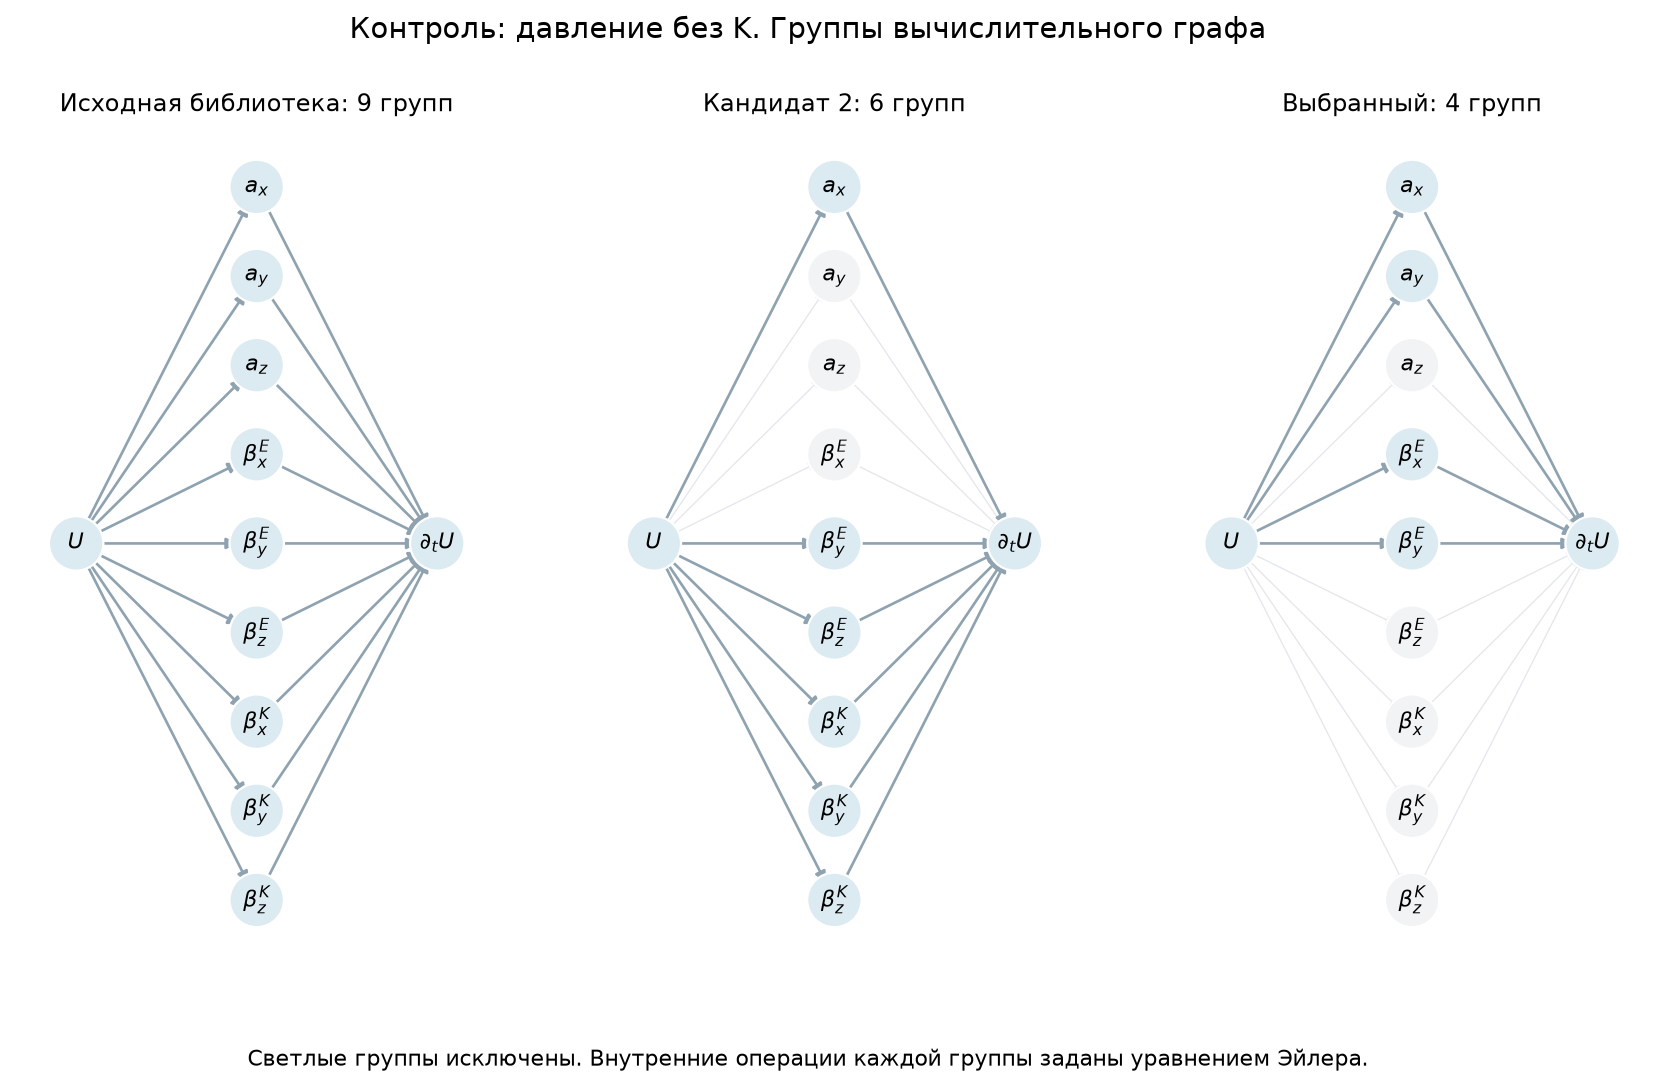

### The Well

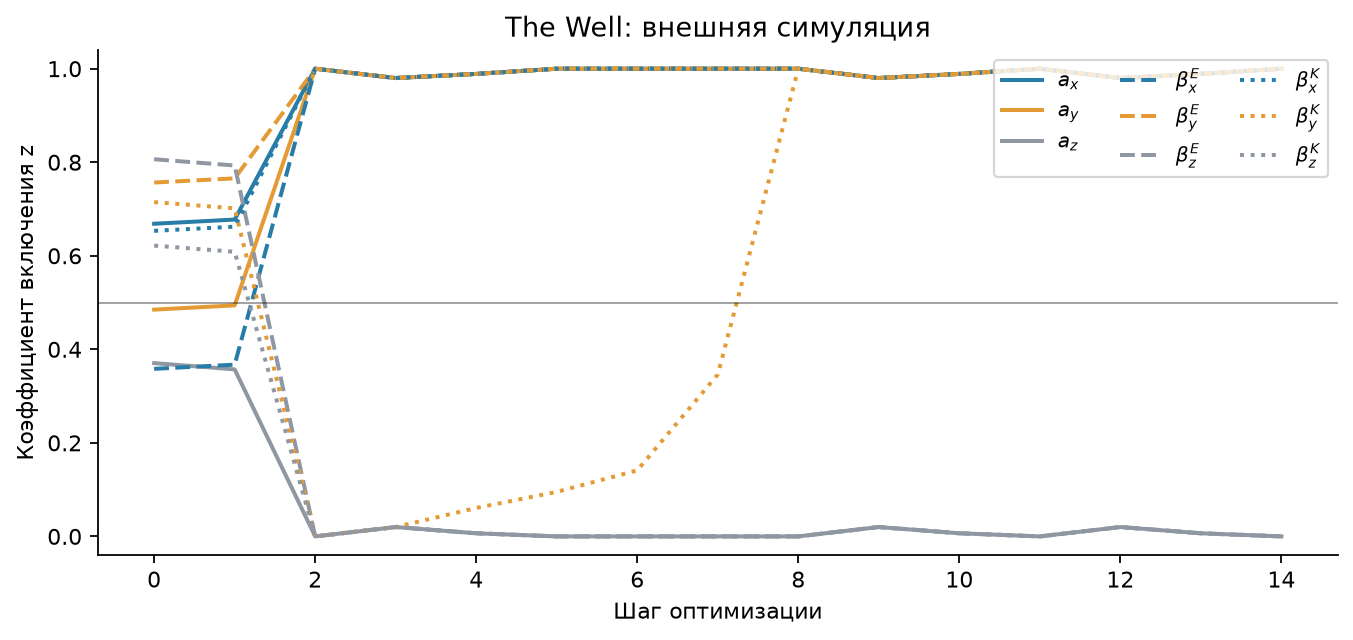

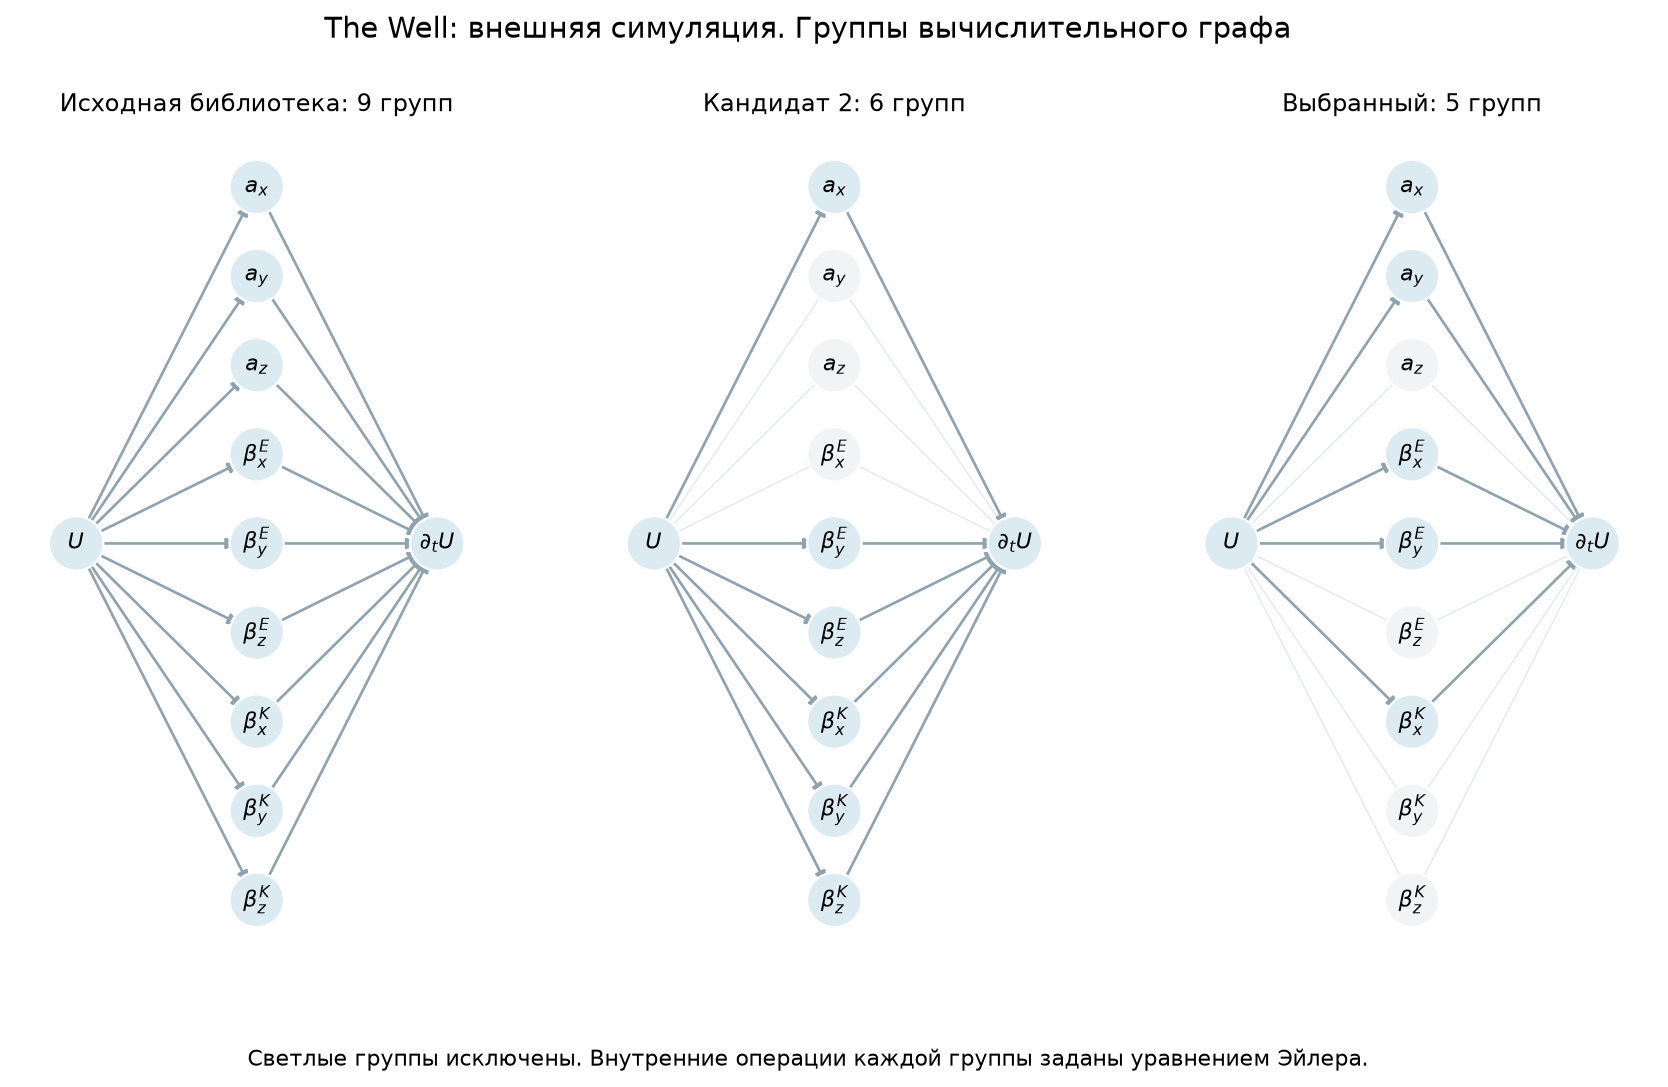

### Как проверки влияют на поиск в The Well

| Шаг | Текущая маска | Группы с q = 1 | Выбор для следующего шага |
| --- | --- | --- | --- |
| 1 | a_x, a_y, a_z, bE_x, bE_y, bE_z, bK_x, bK_y, bK_z | a_x, a_y, bE_x, bE_y, bK_x | a_x, a_y, bE_x, bE_y, bK_x |
| 2 | a_x, a_y, bE_x, bE_y, bK_x | a_x, a_y, bE_x, bE_y, bK_x, bK_y | a_x, a_y, bE_x, bE_y, bK_x |
| 3 | a_x, a_y, bE_x, bE_y, bK_x | a_x, a_y, bE_x, bE_y, bK_x, bK_y | a_x, a_y, bE_x, bE_y, bK_x |
| 4 | a_x, a_y, bE_x, bE_y, bK_x | a_x, a_y, bE_x, bE_y, bK_x, bK_y | a_x, a_y, bE_x, bE_y, bK_x |

In [4]:
for key in metrics["datasets"]:
    display(Markdown(f"### {NAMES[key]}"))
    figure(f"{key}_gates.png")
    figure(f"{key}_graphs.png")

# Проверяем группы с учётом маски текущего шага.
well_rounds = metrics["datasets"]["well"]["runs"][0]["rounds"]
rows = []
for step in well_rounds:
    before = ", ".join(p for p, on in zip(PARAMS, step["mask_before"]) if on)
    supported = ", ".join(p for p, on in zip(PARAMS, step["diagnostics"]["keep"]) if on)
    after = ", ".join(p for p, on in zip(PARAMS, step["selected_mask"]) if on)
    rows.append([step["round"] + 1, before or "пустая", supported or "нет", after or "пустая"])
display(Markdown("### Как проверки влияют на поиск в The Well"))
table(["Шаг", "Текущая маска", "Группы с q = 1", "Выбор для следующего шага"], rows)


## 9. Выбор модели и проверка полным перебором

Для каждого запуска показываем выбранные группы, ошибку и разницу между найденным $S$ и его минимумом по всем маскам. В варианте без интервенционного штрафа $\eta=0$, поэтому минимум перебора для него считаем отдельно.

Относительная $L_2$-ошибка равна $\sqrt{\operatorname{NMSE}}$. В таблице умножаем её на 100%, а $S$ показываем без пересчёта.


| Набор | Метод | Seed | Активные группы | Число | L₂ val | L₂ test | S | Разрыв |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Эйлер, ANU 6 | с интервенциями | 0 | a_x, a_y, bE_x, bE_y, bK_x | 5 | 12.95% | 11.14% | 0.02788 | 0 |
| Эйлер, ANU 6 | с интервенциями | 1 | a_x, a_y, bE_x, bE_y, bK_x | 5 | 12.95% | 11.14% | 0.02788 | 0 |
| Эйлер, ANU 6 | с интервенциями | 2 | a_x, a_y, bE_x, bE_y, bK_x | 5 | 12.95% | 11.14% | 0.02788 | 0 |
| Эйлер, ANU 6 | без интервенций | 0 | a_x, a_y, bE_x, bE_y, bK_x, bK_y | 6 | 11.95% | 9.35% | 0.02761 | 0 |
| Контроль без K в давлении | с интервенциями | 0 | a_x, a_y, bE_x, bE_y | 4 | 11.53% | 8.59% | 0.02218 | 0 |
| Контроль без K в давлении | с интервенциями | 1 | a_x, a_y, bE_x, bE_y | 4 | 11.53% | 8.59% | 0.02218 | 0 |
| Контроль без K в давлении | с интервенциями | 2 | a_x, a_y, bE_x, bE_y | 4 | 11.53% | 8.59% | 0.02218 | 0 |
| Контроль без K в давлении | без интервенций | 0 | a_x, a_y, bE_x, bE_y | 4 | 11.53% | 8.59% | 0.02218 | 0 |
| The Well | с интервенциями | 0 | a_x, a_y, bE_x, bE_y, bK_x | 5 | 10.05% | 10.75% | 0.02120 | 0 |
| The Well | с интервенциями | 1 | a_x, a_y, bE_x, bE_y, bK_x | 5 | 10.05% | 10.75% | 0.02120 | 0 |
| The Well | с интервенциями | 2 | a_x, a_y, bE_x, bE_y, bK_x | 5 | 10.05% | 10.75% | 0.02120 | 0 |
| The Well | без интервенций | 0 | a_x, a_y, bE_x, bE_y, bK_x, bK_y | 6 | 9.32% | 9.36% | 0.02203 | 0.000822 |

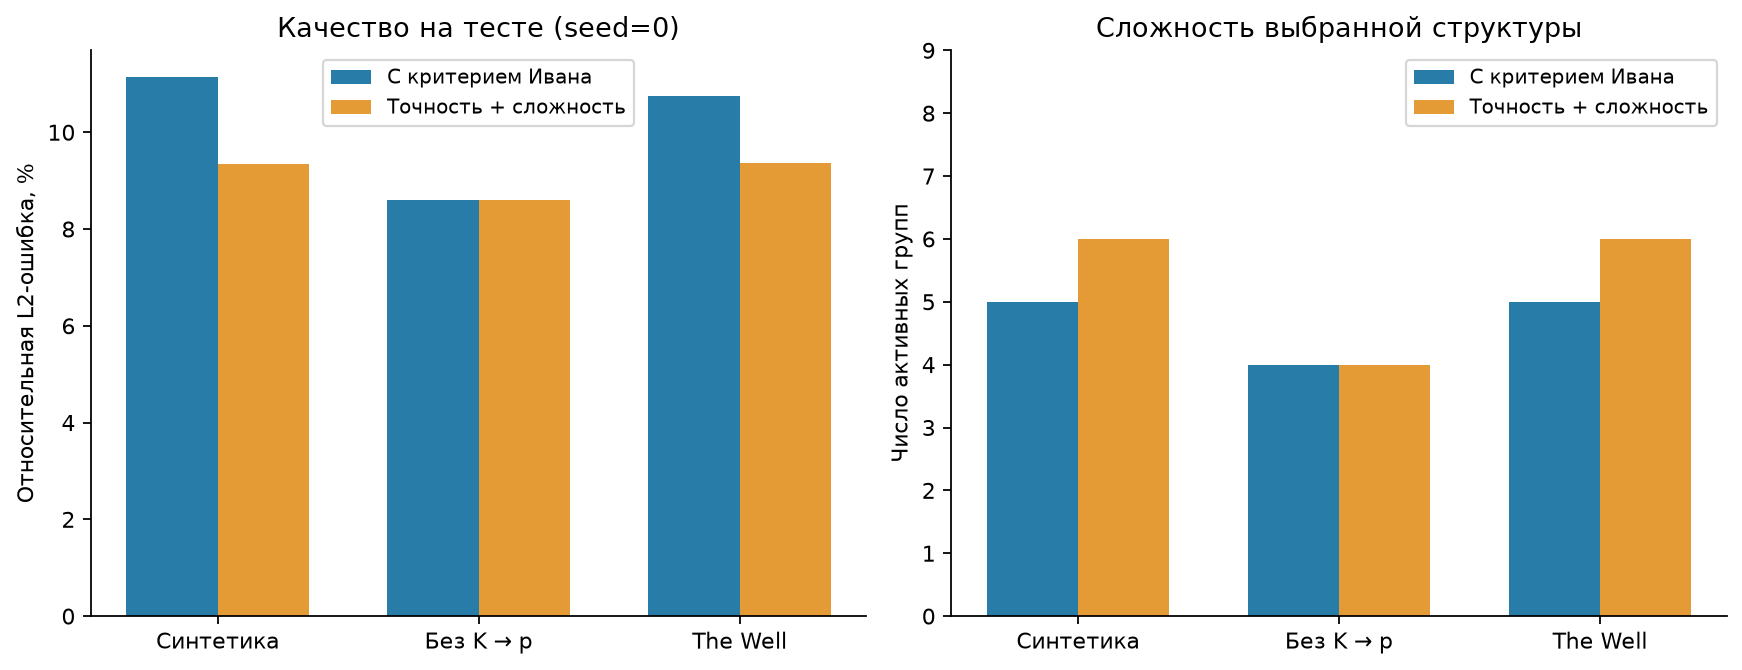

| Коэффициент выбранной модели | Эйлер, ANU 6 | Контроль без K в давлении | The Well |
| --- | --- | --- | --- |
| a_x | 0.97587 | 0.97247 | 1.00563 |
| a_y | 1.00073 | 1.01942 | 0.89821 |
| a_z | 0.00000 | 0.00000 | 0.00000 |
| bE_x | 0.42914 | 0.40484 | 0.39563 |
| bE_y | 0.17747 | 0.35439 | 0.38330 |
| bE_z | 0.00000 | 0.00000 | 0.00000 |
| bK_x | 0.50696 | -0.00000 | 0.40481 |
| bK_y | -0.00000 | 0.00000 | -0.00000 |
| bK_z | 0.00000 | 0.00000 | 0.00000 |

In [5]:
rows = []
for key, item in metrics["datasets"].items():
    for run in item["runs"]:
        mask = np.asarray(run["selected_mask"], dtype=bool)
        rows.append([NAMES[key], METHODS[run["method"]], run["seed"],
                     ", ".join(p for p, on in zip(PARAMS, mask) if on) or "пустая",
                     int(mask.sum()), f"{100*np.sqrt(run['val_nmse']):.2f}%",
                     f"{100*np.sqrt(run['test_nmse']):.2f}%", f"{run['score']:.5f}",
                     f"{run['oracle_gap']:.3g}"])
table(["Набор", "Метод", "Seed", "Активные группы", "Число", "L₂ val", "L₂ test", "S", "Разрыв"], rows)
figure("comparison.png")

rows = [[PARAMS[j], *[f"{item['runs'][0]['coefficients'][j]:.5f}" for item in metrics["datasets"].values()]]
        for j in range(9)]
table(["Коэффициент выбранной модели", *[NAMES[k] for k in metrics["datasets"]]], rows)


В повторных запусках меняем seed поиска и случайной выборки масок. Данные и настройки проверок остаются прежними. Совпадение результатов показывает, насколько поиск зависит от случайного старта. Оно не даёт доверительный интервал для структуры на новых данных.

На тесте оцениваем уже выбранные модели. По его ошибкам не выбираем seed или метод. Основной результат получен в первом заранее заданном запуске с интервенционным штрафом. Другие запуски нужны для проверки повторяемости и сравнения с вариантом без этого штрафа.


Эйлер, ANU 6: различных выбранных масок в трёх запусках = 1
Контроль без K в давлении: различных выбранных масок в трёх запусках = 1
The Well: различных выбранных масок в трёх запусках = 1
Файлы с масками и результатами:
results/lab3/candidate_graphs.jsonl
results/lab3/control_approximation.npz
results/lab3/metrics.json
results/lab3/synthetic_approximation.npz
results/lab3/well_approximation.npz


### Архив кандидатов: Эйлер, ANU 6

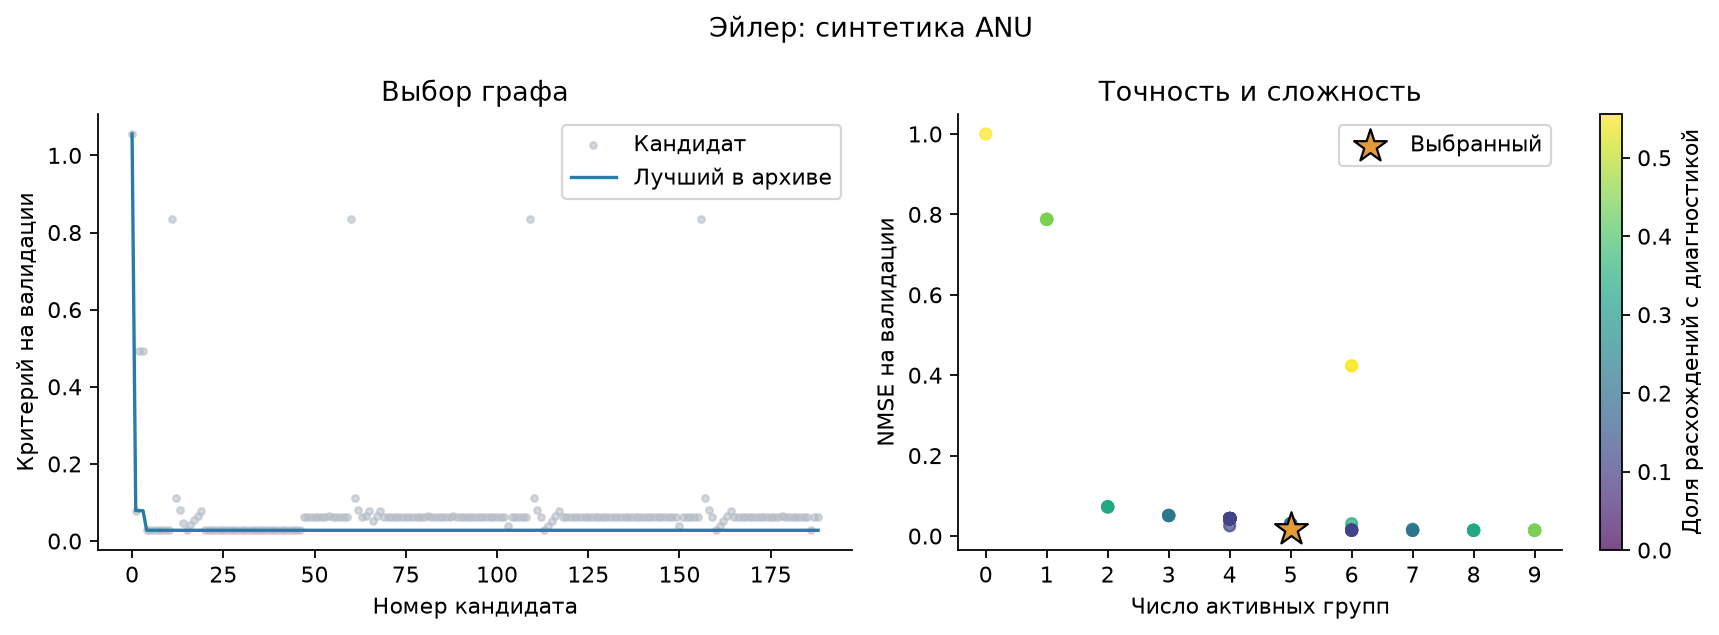

### Архив кандидатов: Контроль без K в давлении

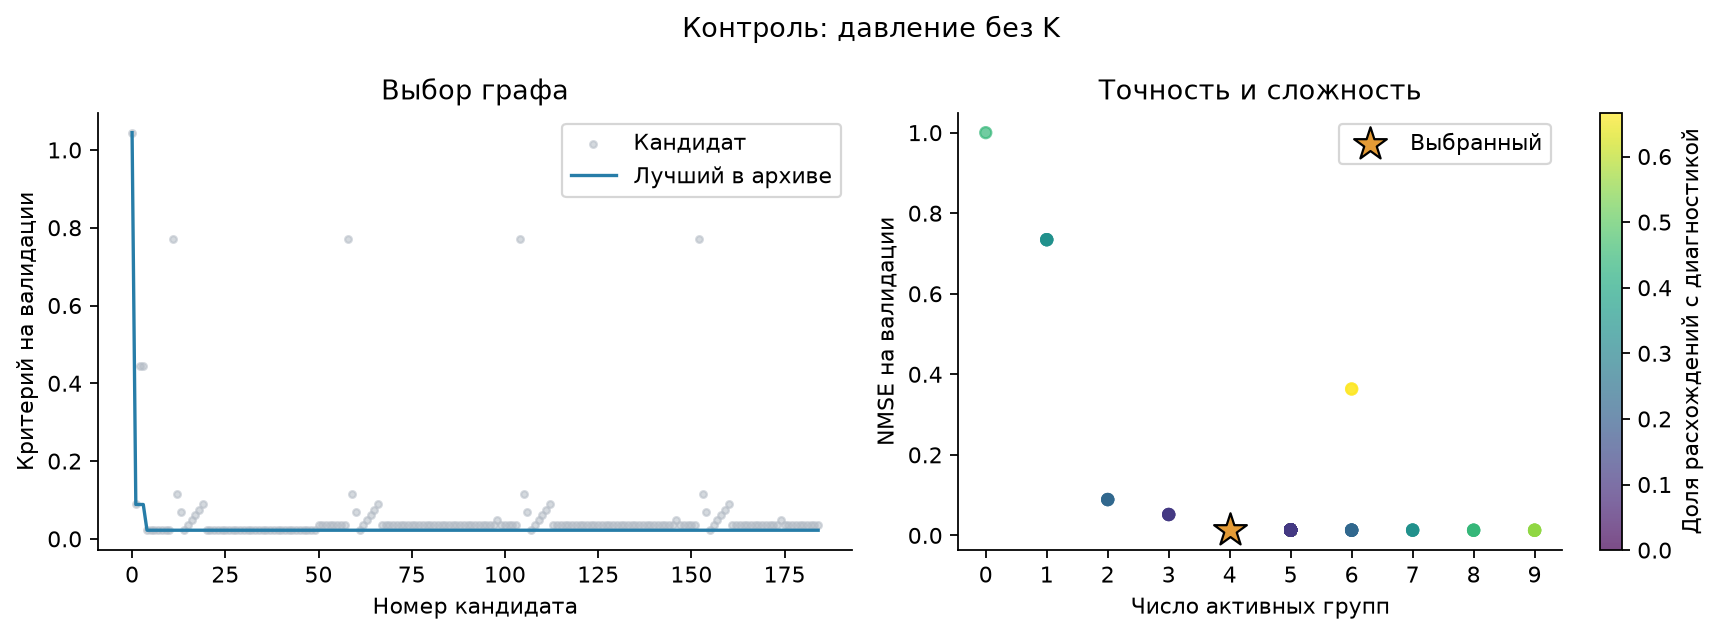

### Архив кандидатов: The Well

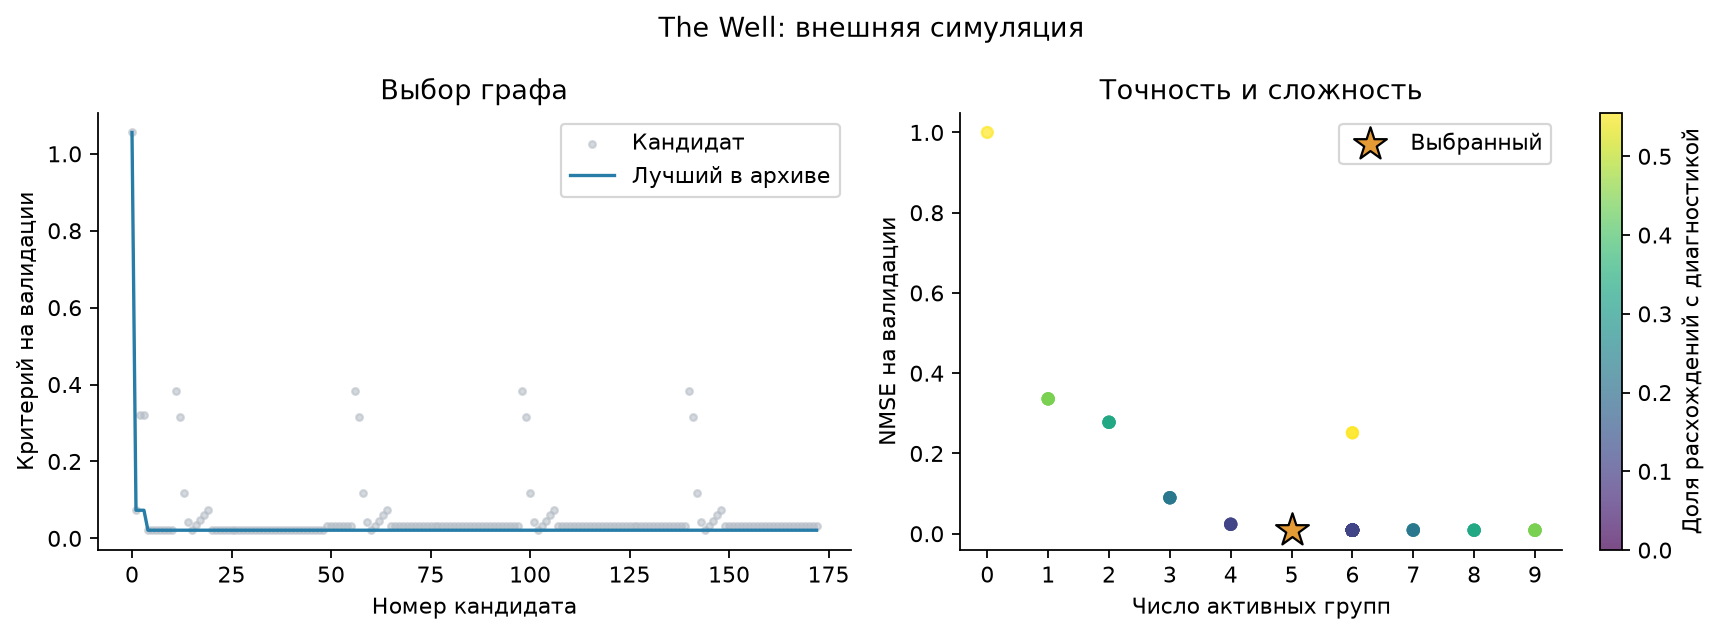

In [6]:
for key, item in metrics["datasets"].items():
    s = item["seed_stability"]
    print(f"{NAMES[key]}: различных выбранных масок в трёх запусках = {s['number_distinct_masks']}")
    display(Markdown(f"### Архив кандидатов: {NAMES[key]}"))
    figure(f"{key}_archive.png")
print("Файлы с масками и результатами:")
for path in sorted(OUT.iterdir()):
    if path.suffix in {".json", ".jsonl", ".npz"}:
        print(path.relative_to(ROOT))


## 10. Предсказание на тесте

На тестовых кадрах сравниваем предсказание со сглаженной производной $\partial_tU$. Проверка относится к правой части уравнения в этих точках. Длительный расчёт течения по выбранной модели и устойчивость его траектории здесь не проверяются.

На рисунках сравниваются производные из данных и выбранной модели. Для нормировки используем масштабы, найденные на обучении. На расхождения влияют выбор структуры, оценки коэффициентов, численное сглаживание решателя и погрешность конечных разностей.


### Эйлер, ANU 6

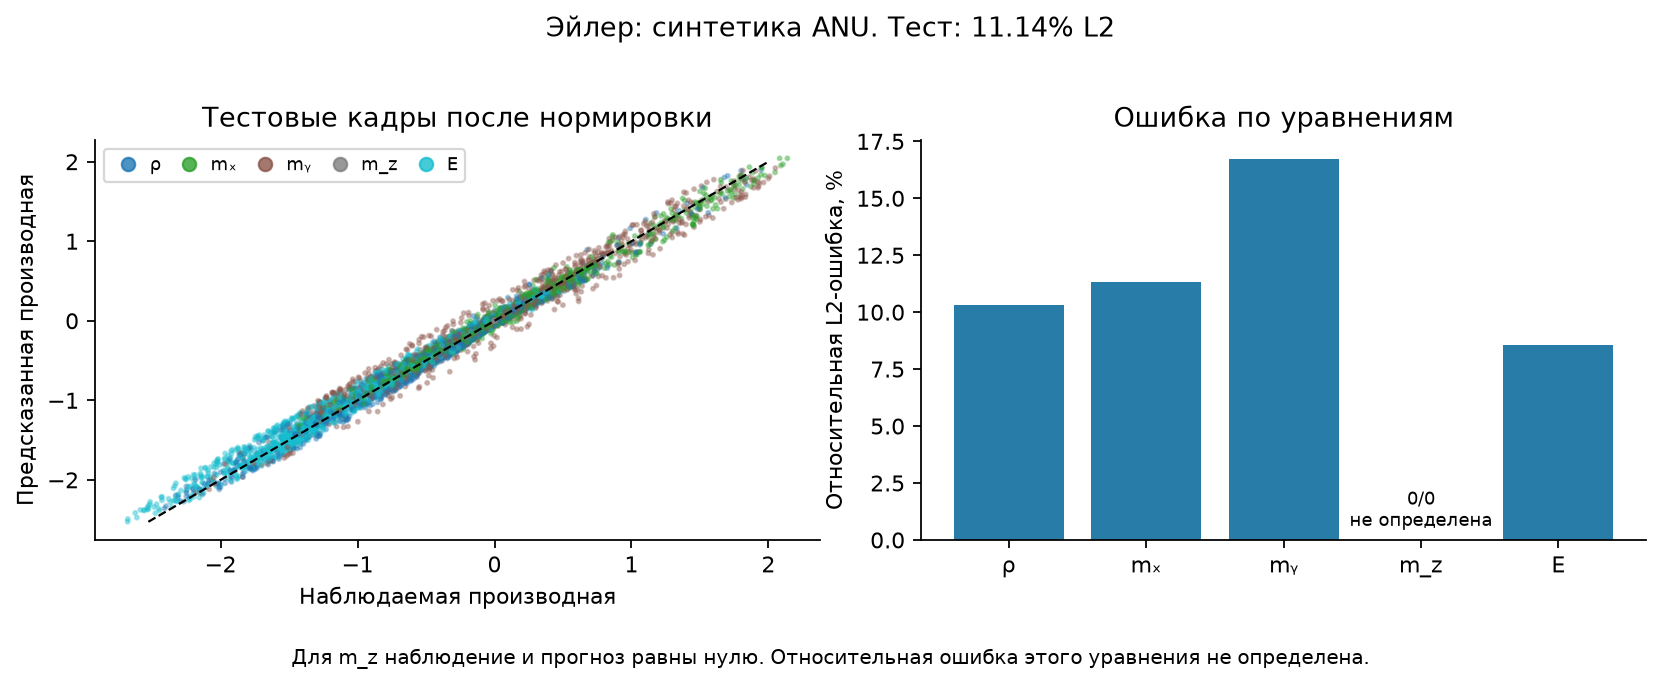

### Контроль без K в давлении

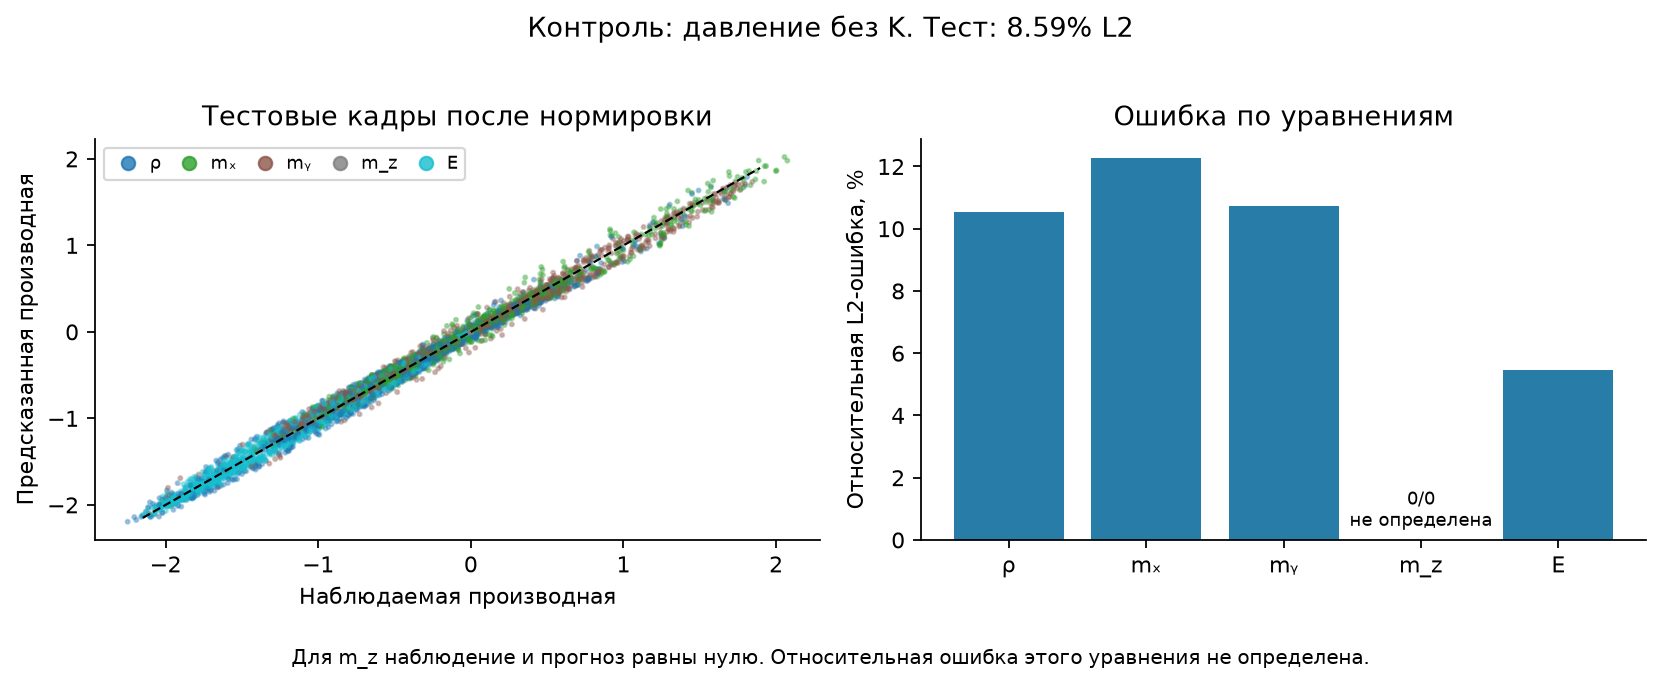

### The Well

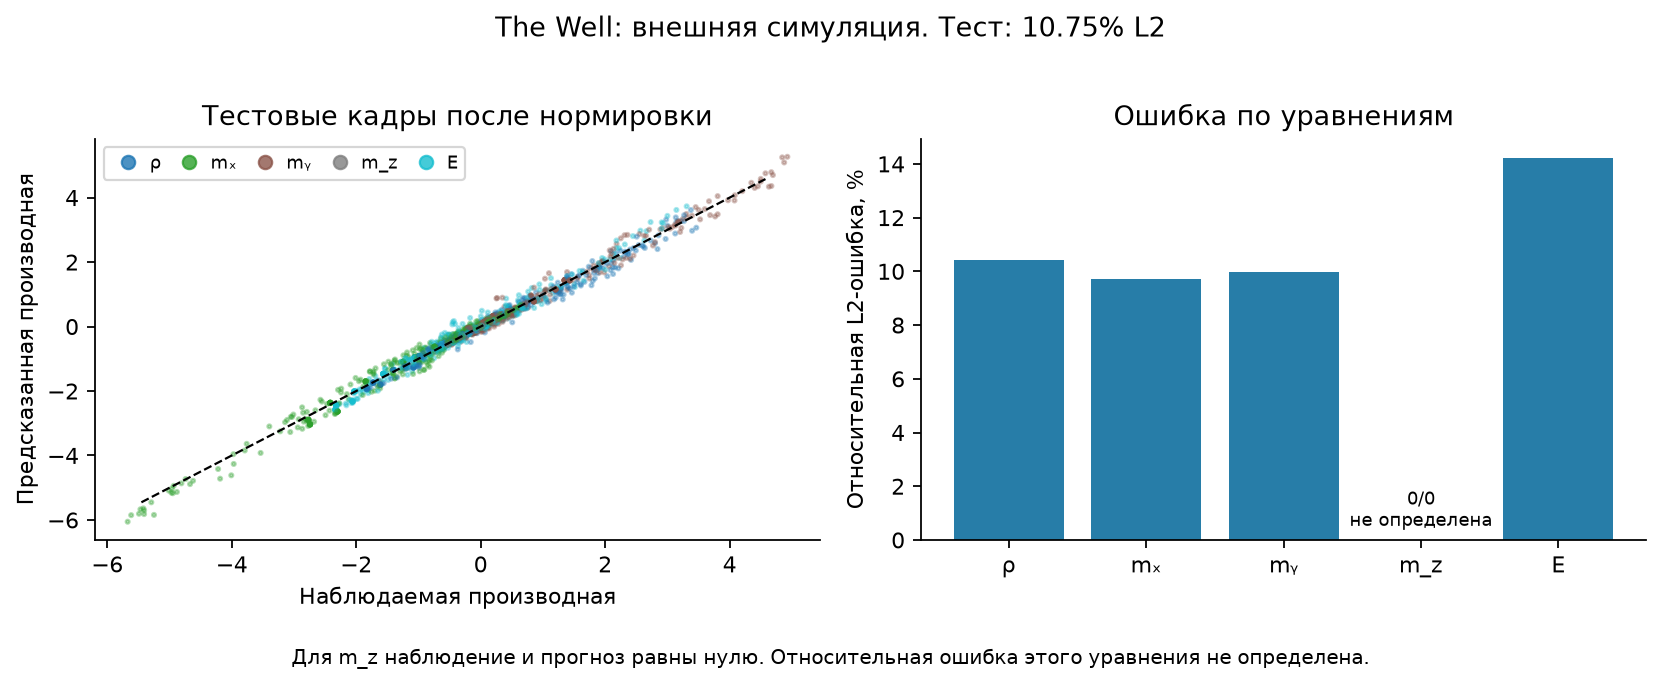

In [7]:
for key in metrics["datasets"]:
    display(Markdown(f"### {NAMES[key]}"))
    figure(f"{key}_fit.png")


## 11. Чувствительность к штрафам

Меняем штрафы за число групп и за несогласие с проверками. Данные и результаты проверок остаются прежними. Для новых штрафов выбираем лучшую маску из того же архива и смотрим, как меняются размер графа и ошибка. Поиск заново не запускаем, поэтому не знаем, какие ещё маски он нашёл бы при этих настройках.

Основные настройки заданы до просмотра теста. По этой таблице их не меняем.


In [8]:
for key, item in metrics["datasets"].items():
    display(Markdown(f"### {NAMES[key]}"))
    rows = [[row["lambda_complexity"], row["lambda_intervention"],
             ", ".join(p for p, on in zip(PARAMS, row["selected_mask"]) if on) or "пустая",
             f"{100*np.sqrt(row['val_nmse']):.2f}%", f"{row['score']:.5f}"]
            for row in item["sensitivity"]["rows"]]
    table(["λ", "η", "Активные группы", "L₂ val", "Критерий"], rows)


### Эйлер, ANU 6

| λ | η | Активные группы | L₂ val | Критерий |
| --- | --- | --- | --- | --- |
| 0.005 | 0.0 | a_x, a_y, bE_x, bE_y, bK_x, bK_y | 11.95% | 0.01761 |
| 0.005 | 0.03 | a_x, a_y, bE_x, bE_y, bK_x | 12.95% | 0.01955 |
| 0.005 | 0.1 | a_x, a_y, bE_x, bE_y, bK_x | 12.95% | 0.01955 |
| 0.005 | 0.3 | a_x, a_y, bE_x, bE_y, bK_x | 12.95% | 0.01955 |
| 0.02 | 0.0 | a_x, a_y, bE_x, bE_y, bK_x, bK_y | 11.95% | 0.02761 |
| 0.02 | 0.03 | a_x, a_y, bE_x, bE_y, bK_x | 12.95% | 0.02788 |
| 0.02 | 0.1 | a_x, a_y, bE_x, bE_y, bK_x | 12.95% | 0.02788 |
| 0.02 | 0.3 | a_x, a_y, bE_x, bE_y, bK_x | 12.95% | 0.02788 |
| 0.08 | 0.0 | a_x, a_y, bE_x, bE_y | 15.97% | 0.06107 |
| 0.08 | 0.03 | a_x, a_y, bE_x, bE_y, bK_x | 12.95% | 0.06122 |
| 0.08 | 0.1 | a_x, a_y, bE_x, bE_y, bK_x | 12.95% | 0.06122 |
| 0.08 | 0.3 | a_x, a_y, bE_x, bE_y, bK_x | 12.95% | 0.06122 |

### Контроль без K в давлении

| λ | η | Активные группы | L₂ val | Критерий |
| --- | --- | --- | --- | --- |
| 0.005 | 0.0 | a_x, a_y, bE_x, bE_y | 11.53% | 0.01552 |
| 0.005 | 0.03 | a_x, a_y, bE_x, bE_y | 11.53% | 0.01552 |
| 0.005 | 0.1 | a_x, a_y, bE_x, bE_y | 11.53% | 0.01552 |
| 0.005 | 0.3 | a_x, a_y, bE_x, bE_y | 11.53% | 0.01552 |
| 0.02 | 0.0 | a_x, a_y, bE_x, bE_y | 11.53% | 0.02218 |
| 0.02 | 0.03 | a_x, a_y, bE_x, bE_y | 11.53% | 0.02218 |
| 0.02 | 0.1 | a_x, a_y, bE_x, bE_y | 11.53% | 0.02218 |
| 0.02 | 0.3 | a_x, a_y, bE_x, bE_y | 11.53% | 0.02218 |
| 0.08 | 0.0 | a_x, a_y, bE_x, bE_y | 11.53% | 0.04885 |
| 0.08 | 0.03 | a_x, a_y, bE_x, bE_y | 11.53% | 0.04885 |
| 0.08 | 0.1 | a_x, a_y, bE_x, bE_y | 11.53% | 0.04885 |
| 0.08 | 0.3 | a_x, a_y, bE_x, bE_y | 11.53% | 0.04885 |

### The Well

| λ | η | Активные группы | L₂ val | Критерий |
| --- | --- | --- | --- | --- |
| 0.005 | 0.0 | a_x, a_y, bE_x, bE_y, bK_x, bK_y | 9.32% | 0.01203 |
| 0.005 | 0.03 | a_x, a_y, bE_x, bE_y, bK_x | 10.05% | 0.01287 |
| 0.005 | 0.1 | a_x, a_y, bE_x, bE_y, bK_x | 10.05% | 0.01287 |
| 0.005 | 0.3 | a_x, a_y, bE_x, bE_y, bK_x | 10.05% | 0.01287 |
| 0.02 | 0.0 | a_x, a_y, bE_x, bE_y, bK_x | 10.05% | 0.02120 |
| 0.02 | 0.03 | a_x, a_y, bE_x, bE_y, bK_x | 10.05% | 0.02120 |
| 0.02 | 0.1 | a_x, a_y, bE_x, bE_y, bK_x | 10.05% | 0.02120 |
| 0.02 | 0.3 | a_x, a_y, bE_x, bE_y, bK_x | 10.05% | 0.02120 |
| 0.08 | 0.0 | a_x, a_y, bE_x, bE_y, bK_x | 10.05% | 0.05454 |
| 0.08 | 0.03 | a_x, a_y, bE_x, bE_y, bK_x | 10.05% | 0.05454 |
| 0.08 | 0.1 | a_x, a_y, bE_x, bE_y, bK_x | 10.05% | 0.05454 |
| 0.08 | 0.3 | a_x, a_y, bE_x, bE_y, bK_x | 10.05% | 0.05454 |

## 12. Итоги эксперимента

Числа и выбранные группы ниже загружаются из результатов расчёта.


In [9]:
for key, item in metrics["datasets"].items():
    first = item["runs"][0]
    keep = [p for p, on in zip(PARAMS, first["selected_mask"]) if on]
    drop = [p for p, on in zip(PARAMS, first["selected_mask"]) if not on]
    lines = [f"**{NAMES[key]}.** Сохраняются: {', '.join(keep) or 'нет'}. "
             f"Исключаются: {', '.join(drop) or 'нет'}.",
             f"Относительная L₂-ошибка на тесте: {100*np.sqrt(first['test_nmse']):.2f}%. "
             f"Разрыв с минимумом дискретного критерия: {first['oracle_gap']:.3g}."]
    ablation = next(run for run in item["runs"] if run["method"] == "ablation")
    error_main = 100*np.sqrt(first["test_nmse"])
    error_ablation = 100*np.sqrt(ablation["test_nmse"])
    comparison = "выше" if error_main > error_ablation + 1e-8 else ("ниже" if error_main < error_ablation - 1e-8 else "такая же")
    lines.append(f"В запуске с интервенционным штрафом тестовая ошибка {comparison}: "
                 f"{error_ablation:.2f}% без штрафа и {error_main:.2f}% с ним. "
                 "Модели выбраны до сравнения тестовых ошибок.")
    if ablation["oracle_gap"] > 1e-9:
        exact = item["oracle"]["ablation"]
        oracle_support = ", ".join(p for p,on in zip(PARAMS,exact["mask"]) if on)
        lines.append(f"Запуск без интервенционного слагаемого не достиг минимума своего критерия: разрыв {ablation['oracle_gap']:.6f}. "
                     f"Полный перебор выбирает {oracle_support}.")
    if key == "well" and item["oracle"]["intervention"]["mask"] == item["oracle"]["ablation"]["mask"]:
        oracle_count = sum(item["oracle"]["intervention"]["mask"])
        lines.append(f"Полный перебор с интервенционным штрафом и без него выбирает одинаковые {oracle_count} групп.")
        if ablation["oracle_gap"] > 1e-9:
            lines.append("Различие двух поисковых запусков связано также с тем, что поиск без штрафа не достиг своего минимума. "
                         "Поэтому разницу тестовых ошибок нельзя объяснять только интервенционным штрафом.")
    if key in {"synthetic", "well"}:
        observable = [0, 1, 3, 4, 6, 7]
        missing = [PARAMS[j] for j in observable if not first["selected_mask"][j]]
        if missing:
            lines.append("Известное уравнение содержит следующие x/y-слагаемые, которые критерий ошибочно удалил: "
                         + ", ".join(missing) + ". Значит, даже найденный минимум критерия не восстановил уравнение полностью.")
    if key == "control":
        absent_found = not first["selected_mask"][6] and not first["selected_mask"][7]
        lines.append("Оба слагаемых кинетической поправки удалены. Это совпадает с уравнением, по которому рассчитан контроль."
                     if absent_found else
                     "Часть кинетической поправки сохранена, хотя её нет в уравнении контрольного расчёта. На этих данных критерий ошибся.")
    display(Markdown("\n\n".join(lines)))


**Эйлер, ANU 6.** Сохраняются: a_x, a_y, bE_x, bE_y, bK_x. Исключаются: a_z, bE_z, bK_y, bK_z.

Относительная L₂-ошибка на тесте: 11.14%. Разрыв с минимумом дискретного критерия: 0.

В запуске с интервенционным штрафом тестовая ошибка выше: 9.35% без штрафа и 11.14% с ним. Модели выбраны до сравнения тестовых ошибок.

Известное уравнение содержит следующие x/y-слагаемые, которые критерий ошибочно удалил: bK_y. Значит, даже найденный минимум критерия не восстановил уравнение полностью.

**Контроль без K в давлении.** Сохраняются: a_x, a_y, bE_x, bE_y. Исключаются: a_z, bE_z, bK_x, bK_y, bK_z.

Относительная L₂-ошибка на тесте: 8.59%. Разрыв с минимумом дискретного критерия: 0.

В запуске с интервенционным штрафом тестовая ошибка такая же: 8.59% без штрафа и 8.59% с ним. Модели выбраны до сравнения тестовых ошибок.

Оба слагаемых кинетической поправки удалены. Это совпадает с уравнением, по которому рассчитан контроль.

**The Well.** Сохраняются: a_x, a_y, bE_x, bE_y, bK_x. Исключаются: a_z, bE_z, bK_y, bK_z.

Относительная L₂-ошибка на тесте: 10.75%. Разрыв с минимумом дискретного критерия: 0.

В запуске с интервенционным штрафом тестовая ошибка выше: 9.36% без штрафа и 10.75% с ним. Модели выбраны до сравнения тестовых ошибок.

Запуск без интервенционного слагаемого не достиг минимума своего критерия: разрыв 0.000822. Полный перебор выбирает a_x, a_y, bE_x, bE_y, bK_x.

Полный перебор с интервенционным штрафом и без него выбирает одинаковые 5 групп.

Различие двух поисковых запусков связано также с тем, что поиск без штрафа не достиг своего минимума. Поэтому разницу тестовых ошибок нельзя объяснять только интервенционным штрафом.

Известное уравнение содержит следующие x/y-слагаемые, которые критерий ошибочно удалил: bK_y. Значит, даже найденный минимум критерия не восстановил уравнение полностью.

В сравниваемых запусках вариант с интервенционным штрафом дал большую тестовую ошибку на синтетике и The Well. На контроле ошибки совпали, оба варианта правильно удалили отсутствующие кинетические слагаемые.

На синтетике оба поиска достигли минимумов своих критериев. Штраф изменил выбранную маску и удалил нужную группу. На The Well минимумы обоих критериев соответствуют одной маске без этой группы. Поиск без штрафа сохранил шестую группу и получил меньшую тестовую ошибку, но не достиг минимума своего критерия. Здесь сравнение двух запусков смешивает влияние штрафа и ошибку поиска.

Алгоритм проверяет группы, обновляет $z$, получает бинарные маски, подбирает их веса и выбирает граф из архива. Проверки из второй работы влияют и на следующие шаги поиска, и на окончательный выбор.

Ограничения:

- Выбор ограничен девятью группами уравнения Эйлера. Произвольный причинный граф между наблюдаемыми величинами не ищем.
- Перемешивание при прежнем отклике проверяет чувствительность модели. Для вывода о физических причинных эффектах нужны другие данные и дополнительные предположения.
- По двумерным данным нельзя проверить необходимость $z$-слагаемых в трёхмерном течении.
- Производные приближены гауссовым сглаживанием и конечными разностями. Интегральная схема WSINDy целиком не реализована.
- Порог бутстрепа найден по данным. На него могут влиять ошибка сетки и зависимость между блоками.
- The Well получен численным расчётом. Если задание требует физических измерений, такой набор ещё нужно добавить.
- Минимум выбранного критерия может соответствовать неверной структуре, как видно на обычной синтетике и The Well.


## Источники

1. И. Папай. [Лабораторная работа № 2 и исходный код](https://github.com/papayiv/euler-quadrants-lab/tree/c401635cd8966dec498f17dcff242a3b705fde29), 2026. Библиотека слагаемых, интервенционная диагностика и контроль без кинетической поправки.
2. C. Louizos, M. Welling, D. P. Kingma. [Learning Sparse Neural Networks through $L_0$ Regularization](https://arxiv.org/abs/1712.01312). ICLR, 2018. Непрерывные коэффициенты включения для структурной регуляризации.
3. Y. Yamada, O. Lindenbaum, S. Negahban, Y. Kluger. [Feature Selection using Stochastic Gates](https://proceedings.mlr.press/v119/yamada20a.html). ICML, 2020. Релаксация бинарного выбора признаков.
4. C. Strobl et al. [Conditional variable importance for random forests](https://doi.org/10.1186/1471-2105-9-307). BMC Bioinformatics, 2008. Условное перемешивание как средство оценки важности переменной.
5. H. R. Künsch. *The jackknife and the bootstrap for general stationary observations*. Annals of Statistics 17(3), 1217-1241, 1989. Бутстреп зависимых наблюдений.
6. D. A. Messenger, D. M. Bortz. [Weak SINDy for partial differential equations](https://doi.org/10.1016/j.jcp.2021.110525). Journal of Computational Physics, 2021. Поиск уравнений в частных производных по слабой форме.
7. R. Ohana et al. [The Well: a Large-Scale Collection of Diverse Physics Simulations for Machine Learning](https://arxiv.org/abs/2412.00568), 2024. Внешняя численная траектория.
8. R. Liska, B. Wendroff. *Comparison of several difference schemes on 1D and 2D test problems for the Euler equations*. SIAM Journal on Scientific Computing, 2003. [Начальные условия ANU / Fyris](https://www.mso.anu.edu.au/fyris/lw2driemann.html).
9. В. В. Стрижов. Материалы лабораторной работы № 3 и пояснение от 4 ноября 2026 года. Выбор структуры причинно-следственной модели в цикле порождения и выбора моделей.
